# Predicting Four-Hour A&E Breaches with Queue-Informed Synthetic Data

This notebook trains on a transparent queue-informed simulation, not the NHS Artificial HES extract. It predicts `AE_Time_Mins > 240` using only variables available at arrival. It does **not** provide clinical advice or a deployable triage tool.

In [1]:
from pathlib import Path
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, ConfusionMatrixDisplay, roc_auc_score,
                             RocCurveDisplay)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 20261014
sns.set_theme(style='whitegrid')
PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
DATA_ROOT = Path(r'D:\NHS_AE_ML_Data')
DATA_PATH = DATA_ROOT / 'processed' / 'simulated_ed_attendances.parquet'
assert DATA_PATH.exists(), 'Run ../src/generate_simulated_ed_data.py first, with the same AE_DATA_DIR if you use an external drive.'
df = pd.read_parquet(DATA_PATH)
print(f'Loaded {len(df):,} sampled attendances and {df.shape[1]} columns.')

Loaded 150,000 sampled attendances and 9 columns.


## 1. Schema and data-quality audit

The audit is deliberate: field names are validated rather than assumed. Variables created after departure are not predictors.

In [2]:
print('Columns:', df.columns.tolist())
display(df.head())
audit = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing_n': df.isna().sum(),
                      'missing_pct': (100 * df.isna().mean()).round(2)})
display(audit.sort_values('missing_pct', ascending=False))
print('Exact duplicate rows:', int(df.duplicated().sum()))

required = {'AE_Time_Mins', 'AE_Arrive_Date', 'AE_Arrive_HourOfDay', 'Age_Band'}
missing = required - set(df.columns)
if missing:
    raise ValueError(f'Required fields are missing: {sorted(missing)}')

triage_candidates = [c for c in df.columns if 'triage' in c.lower()]
print('Triage-like fields found:', triage_candidates or 'None - document this limitation.')

Columns: ['Age_Band', 'Sex', 'AE_Arrive_Date', 'AE_Arrive_HourOfDay', 'AE_Arrival_Mode', 'Triage_Category', 'Staff_On_Shift', 'Recent_Arrivals_60m', 'AE_Time_Mins']


,Age_Band,Sex,AE_Arrive_Date,AE_Arrive_HourOfDay,AE_Arrival_Mode,Triage_Category,Staff_On_Shift,Recent_Arrivals_60m,AE_Time_Mins
0,65+,Male,2025-03-02,18,Walk-in,2,8,25,214
1,40-64,Female,2025-03-12,21,Walk-in,2,7,18,139
2,16-39,Female,2025-02-23,20,Walk-in,1,7,16,306
3,0-15,Female,2025-02-12,6,Walk-in,3,5,14,239
4,16-39,Female,2025-01-16,11,Walk-in,3,7,16,181


,dtype,missing_n,missing_pct
Age_Band,str,0,0.0
Sex,str,0,0.0
AE_Arrive_Date,str,0,0.0
AE_Arrive_HourOfDay,int64,0,0.0
AE_Arrival_Mode,str,0,0.0
Triage_Category,str,0,0.0
Staff_On_Shift,int64,0,0.0
Recent_Arrivals_60m,int64,0,0.0
AE_Time_Mins,int64,0,0.0


Exact duplicate rows: 41
Triage-like fields found: ['Triage_Category']


## 2. Cleaning and arrival-time feature engineering

`breach_4h` is the target. Durations at or below zero and implausibly long values are set aside after inspection. The feature list contains only arrival-time variables.

Analytic sample: 149,959; 4-hour breach prevalence: 31.8%


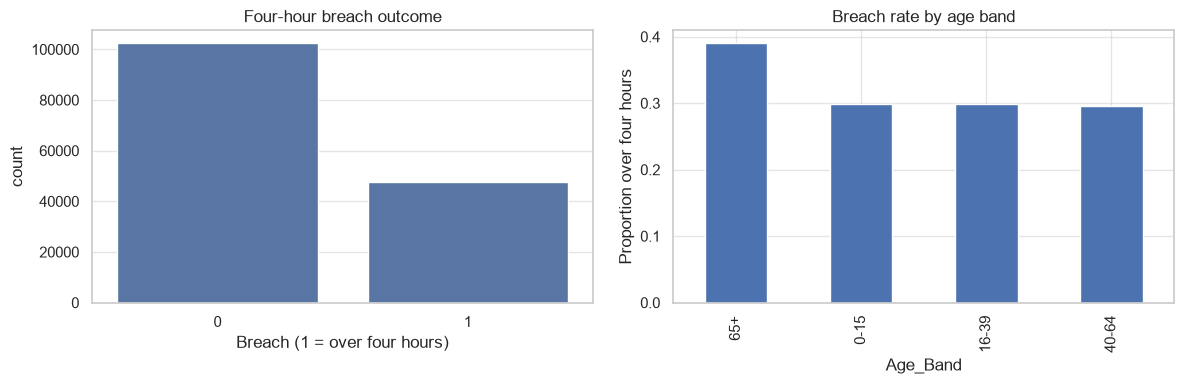

In [3]:
analysis = df.drop_duplicates().copy()
analysis['AE_Time_Mins'] = pd.to_numeric(analysis['AE_Time_Mins'], errors='coerce')
analysis['arrival_date'] = pd.to_datetime(analysis['AE_Arrive_Date'], errors='coerce')
analysis['arrival_hour'] = pd.to_numeric(analysis['AE_Arrive_HourOfDay'], errors='coerce')

# Transparent exclusions: review the counts before changing these thresholds.
analysis = analysis.loc[analysis['AE_Time_Mins'].between(1, 24 * 60)].copy()
analysis = analysis.loc[analysis['arrival_hour'].between(0, 23) | analysis['arrival_hour'].isna()].copy()
analysis['breach_4h'] = (analysis['AE_Time_Mins'] > 240).astype(int)
analysis['night_arrival'] = analysis['arrival_hour'].between(0, 6, inclusive='both').astype('Int64')
analysis['weekend'] = (analysis['arrival_date'].dt.dayofweek >= 5).astype('Int64')
analysis['month'] = analysis['arrival_date'].dt.month.astype('Int64')
analysis['season'] = analysis['month'].map({12: 'winter', 1: 'winter', 2: 'winter', 3: 'spring', 4: 'spring', 5: 'spring', 6: 'summer', 7: 'summer', 8: 'summer', 9: 'autumn', 10: 'autumn', 11: 'autumn'}).astype('string')
print(f'Analytic sample: {len(analysis):,}; 4-hour breach prevalence: {analysis.breach_4h.mean():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=analysis, x='breach_4h', ax=axes[0])
axes[0].set(title='Four-hour breach outcome', xlabel='Breach (1 = over four hours)')
if 'Age_Band' in analysis:
    rates = analysis.groupby('Age_Band', dropna=False)['breach_4h'].mean().sort_values(ascending=False)
    rates.plot.bar(ax=axes[1], title='Breach rate by age band', ylabel='Proportion over four hours')
plt.tight_layout()

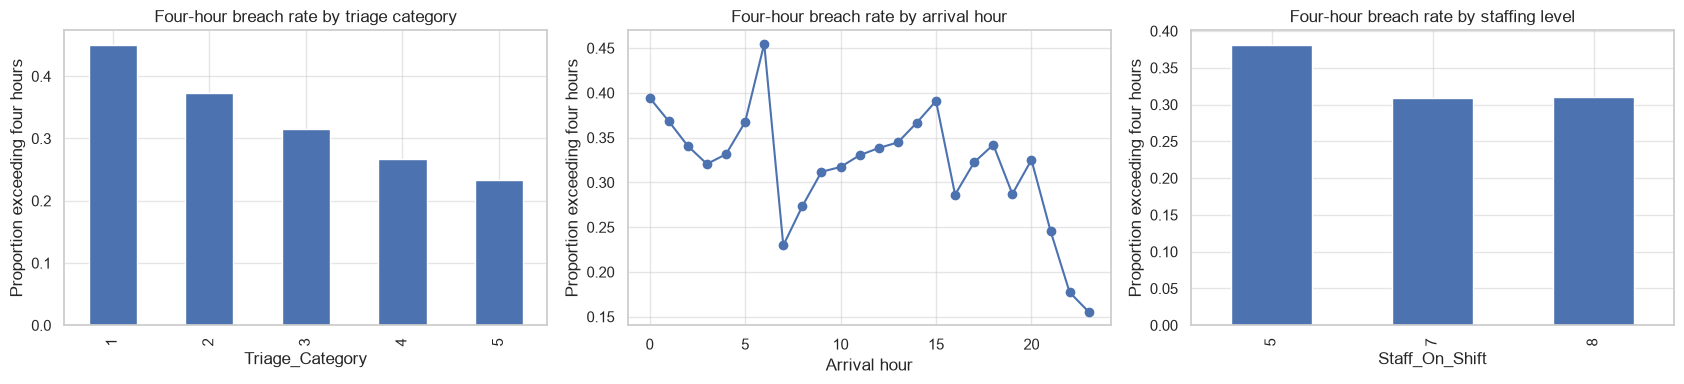

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

analysis.groupby('Triage_Category')['breach_4h'].mean().plot.bar(
    ax=axes[0], title='Four-hour breach rate by triage category',
    ylabel='Proportion exceeding four hours'
)

analysis.groupby('arrival_hour')['breach_4h'].mean().plot(
    ax=axes[1], marker='o', title='Four-hour breach rate by arrival hour',
    xlabel='Arrival hour', ylabel='Proportion exceeding four hours'
)

analysis.groupby('Staff_On_Shift')['breach_4h'].mean().plot.bar(
    ax=axes[2], title='Four-hour breach rate by staffing level',
    ylabel='Proportion exceeding four hours'
)

plt.tight_layout()

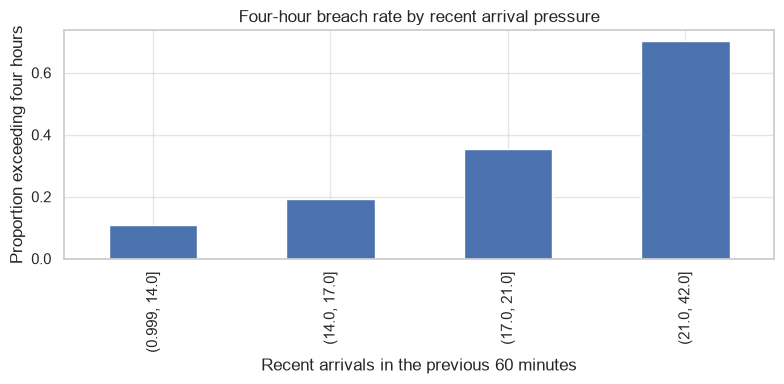

In [5]:
analysis['arrival_pressure_band'] = pd.qcut(
    analysis['Recent_Arrivals_60m'],
    q=4,
    duplicates='drop'
)

analysis.groupby('arrival_pressure_band', observed=True)['breach_4h'].mean().plot.bar(
    figsize=(8, 4),
    title='Four-hour breach rate by recent arrival pressure',
    xlabel='Recent arrivals in the previous 60 minutes',
    ylabel='Proportion exceeding four hours'
)

plt.tight_layout()

## 3. Leakage-controlled modelling data

The source duration and all post-visit information are excluded. A triage variable is appended only when the schema confirms that it exists and is valid for initial assessment.

In [6]:
candidate_features = ['Age_Band', 'Sex', 'arrival_hour', 'night_arrival', 'weekend', 'month',
                      'season', 'AE_Arrival_Mode', 'Staff_On_Shift', 'Recent_Arrivals_60m']
available_features = [c for c in candidate_features if c in analysis.columns]
if triage_candidates:
    # Confirm documentation before allowing the first candidate into the model.
    available_features.append(triage_candidates[0])

X = analysis[available_features].copy()
y = analysis['breach_4h'].copy()
categorical = X.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
numeric = [c for c in X.columns if c not in categorical]
print('Predictors:', available_features)
print('Categorical:', categorical)
print('Numeric:', numeric)

Predictors: ['Age_Band', 'Sex', 'arrival_hour', 'night_arrival', 'weekend', 'month', 'season', 'AE_Arrival_Mode', 'Staff_On_Shift', 'Recent_Arrivals_60m', 'Triage_Category']
Categorical: ['Age_Band', 'Sex', 'season', 'AE_Arrival_Mode', 'Triage_Category']
Numeric: ['arrival_hour', 'night_arrival', 'weekend', 'month', 'Staff_On_Shift', 'Recent_Arrivals_60m']


## 4. Train/validation/test split

A chronological split is preferred so later records are held out. If dates are unusable, the fallback is a stratified random split and must be stated in the report.

In [7]:
usable_dates = analysis['arrival_date'].notna().mean() >= 0.95
if usable_dates:
    order = analysis['arrival_date'].sort_values().index
    n = len(order); train_end, valid_end = int(n * .70), int(n * .85)
    train_idx, valid_idx, test_idx = order[:train_end], order[train_end:valid_end], order[valid_end:]
    X_train, X_valid, X_test = X.loc[train_idx], X.loc[valid_idx], X.loc[test_idx]
    y_train, y_valid, y_test = y.loc[train_idx], y.loc[valid_idx], y.loc[test_idx]
    split_note = 'Chronological 70/15/15 split'
else:
    X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=.30, stratify=y, random_state=SEED)
    X_valid, X_test, y_valid, y_test = train_test_split(X_hold, y_hold, test_size=.50, stratify=y_hold, random_state=SEED)
    split_note = 'Stratified random fallback split'
print(split_note, '| train/validation/test:', len(X_train), len(X_valid), len(X_test))

Chronological 70/15/15 split | train/validation/test: 104971 22494 22494


## 5. Logistic regression and random forest

Parameters are intentionally modest. Use validation performance to select a model; do not tune against the test set.

In [8]:
preprocess_linear = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical),
])
preprocess_tree = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median'))]), numeric),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical),
])

models = {
    'Logistic regression': Pipeline([('prep', preprocess_linear), ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED))]),
    'Random forest': Pipeline([('prep', preprocess_tree), ('model', RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED))]),
}
validation = []
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_valid)[:, 1]
    validation.append({'model': name, 'validation_roc_auc': roc_auc_score(y_valid, p),
                       'validation_pr_auc': average_precision_score(y_valid, p)})
validation = pd.DataFrame(validation).sort_values('validation_roc_auc', ascending=False)
display(validation)

,model,validation_roc_auc,validation_pr_auc
0,Logistic regression,0.853702,0.724221
1,Random forest,0.850792,0.714116


## 6. Final held-out evaluation and interpretation

Evaluate the selected model once on the test set. Permutation importance is reported as predictive importance, not causal effect.

Chosen model: Logistic regression
Test ROC-AUC: 0.853
Test PR-AUC:  0.728


,feature,mean_auc_drop
9,Recent_Arrivals_60m,0.291583
8,Staff_On_Shift,0.057996
7,AE_Arrival_Mode,0.038212
0,Age_Band,0.005405
10,Triage_Category,0.005237
3,night_arrival,0.000183
4,weekend,0.000061
1,Sex,0.000006
6,season,0.000000
5,month,0.000000


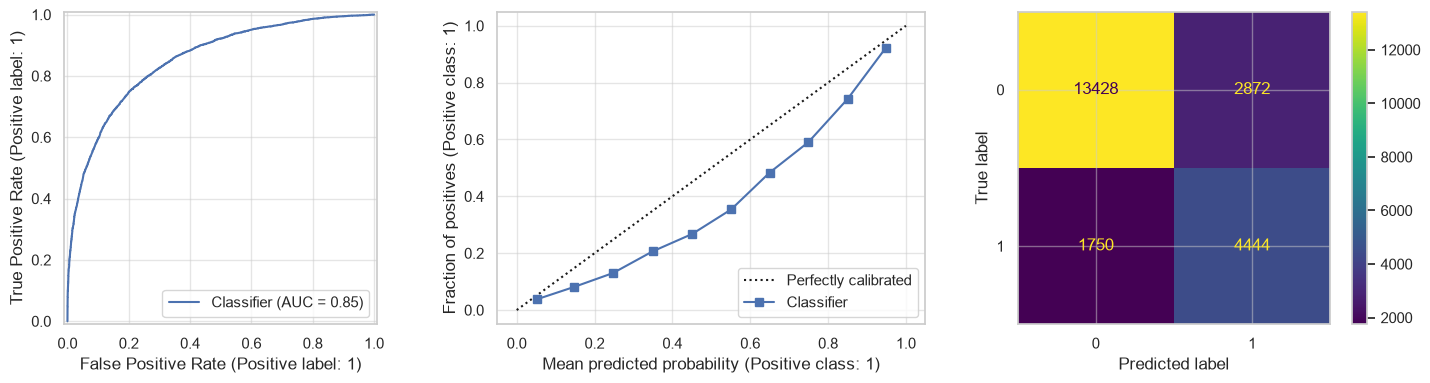

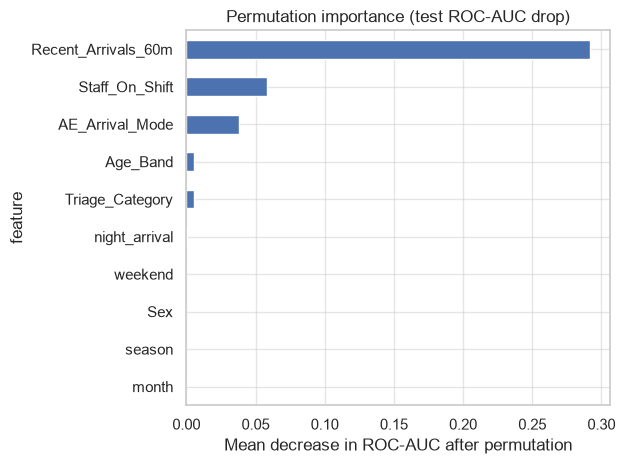

In [9]:
best_name = validation.iloc[0]['model']
best_model = models[best_name]
test_probability = best_model.predict_proba(X_test)[:, 1]
print(f'Chosen model: {best_name}')
print(f'Test ROC-AUC: {roc_auc_score(y_test, test_probability):.3f}')
print(f'Test PR-AUC:  {average_precision_score(y_test, test_probability):.3f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[0])
CalibrationDisplay.from_predictions(y_test, test_probability, n_bins=10, ax=axes[1])
ConfusionMatrixDisplay.from_predictions(y_test, (test_probability >= .5).astype(int), ax=axes[2])
plt.tight_layout()

# Use one process: Windows joblib parallelism can fail when the temporary path contains non-ASCII characters.
importance = permutation_importance(best_model, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'feature': X_test.columns, 'mean_auc_drop': importance.importances_mean}).sort_values('mean_auc_drop', ascending=False)
display(importance_table)
importance_table.head(10).sort_values('mean_auc_drop').plot.barh(x='feature', y='mean_auc_drop', legend=False, title='Permutation importance (test ROC-AUC drop)')
plt.xlabel('Mean decrease in ROC-AUC after permutation')
plt.tight_layout()